In [5]:
!pip install -q datasets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 17.5 MB/s eta 0:00:00


In [9]:
import pandas as pd

url = "https://huggingface.co/datasets/takala/financial_phrasebank/resolve/refs%2Fpr%2F10/sentences_50agree/train-00000-of-00001.parquet"

df = pd.read_parquet(url)

print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nDuplicate sentences:", df["sentence"].duplicated().sum())
print("\nSentiment counts:\n", df["label"].value_counts())
print("\nSample data:\n", df.head())

Dataset shape: (4846, 2)

Columns: ['sentence', 'label']

Duplicate sentences: 8

Sentiment counts:
 label
1    2879
2    1363
0     604
Name: count, dtype: int64

Sample data:
                                             sentence  label
0  According to Gran , the company has no plans t...      1
1  Technopolis plans to develop in stages an area...      1
2  The international electronic industry company ...      0
3  With the new production plant the company woul...      2
4  According to the company 's updated strategy f...      2


In [10]:
# Remove duplicate sentences
df = df.drop_duplicates(subset="sentence").reset_index(drop=True)

# Map numeric labels to sentiment names
df["sentiment"] = df["label"].map({
    0: "negative",
    1: "neutral",
    2: "positive"
})

# Check dataset
print("Dataset shape after cleaning:", df.shape)
print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

print("\nSample data:")
print(df[["sentence", "sentiment"]].head())

Dataset shape after cleaning: (4838, 3)

Sentiment distribution:
sentiment
neutral     2872
positive    1362
negative     604
Name: count, dtype: int64

Missing values:
sentence     0
label        0
sentiment    0
dtype: int64

Sample data:
                                            sentence sentiment
0  According to Gran , the company has no plans t...   neutral
1  Technopolis plans to develop in stages an area...   neutral
2  The international electronic industry company ...  negative
3  With the new production plant the company woul...  positive
4  According to the company 's updated strategy f...  positive


In [11]:

from sklearn.model_selection import train_test_split

# Input text and target labels
X = df["sentence"]
y = df["label"]

# Fixed 80:20 split with balanced class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Total samples:", len(df))
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining sentiment distribution:")
print(y_train.map({
    0: "negative",
    1: "neutral",
    2: "positive"
}).value_counts())

print("\nTesting sentiment distribution:")
print(y_test.map({
    0: "negative",
    1: "neutral",
    2: "positive"
}).value_counts())


Total samples: 4838
Training samples: 3870
Testing samples: 968

Training sentiment distribution:
label
neutral     2297
positive    1090
negative     483
Name: count, dtype: int64

Testing sentiment distribution:
label
neutral     575
positive    272
negative    121
Name: count, dtype: int64


LOGISTIC REGRESSION + TF-IDF
----------------------------------------
Accuracy : 0.7624
Precision: 0.7747
Recall   : 0.7624
F1-score : 0.7429
Training time: 2.8 seconds

Classification Report:
              precision    recall  f1-score   support

    Negative       0.88      0.42      0.57       121
     Neutral       0.75      0.95      0.84       575
    Positive       0.79      0.51      0.62       272

    accuracy                           0.76       968
   macro avg       0.80      0.63      0.68       968
weighted avg       0.77      0.76      0.74       968



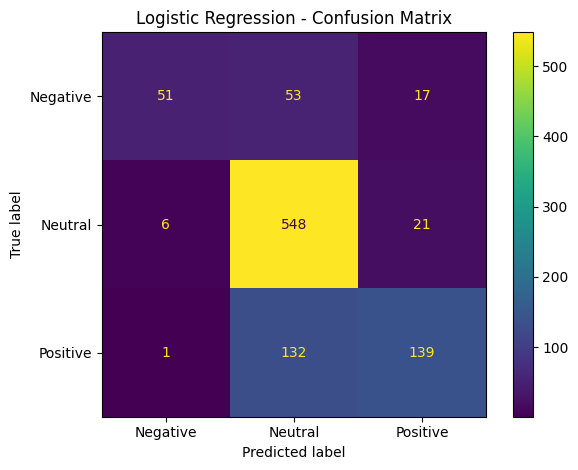

In [12]:

import time
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Build Logistic Regression pipeline
lr_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train model and measure time
start_time = time.time()
lr_model.fit(X_train, y_train)
lr_training_time = time.time() - start_time

# Predict test labels
lr_pred = lr_model.predict(X_test)

# Evaluate model
print("LOGISTIC REGRESSION + TF-IDF")
print("-" * 40)
print("Accuracy :", round(accuracy_score(y_test, lr_pred), 4))
print("Precision:", round(precision_score(
    y_test, lr_pred, average="weighted", zero_division=0
), 4))
print("Recall   :", round(recall_score(
    y_test, lr_pred, average="weighted", zero_division=0
), 4))
print("F1-score :", round(f1_score(
    y_test, lr_pred, average="weighted", zero_division=0
), 4))
print("Training time:", round(lr_training_time, 2), "seconds")

print("\nClassification Report:")
print(classification_report(
    y_test,
    lr_pred,
    labels=[0, 1, 2],
    target_names=["Negative", "Neutral", "Positive"],
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_test, lr_pred, labels=[0, 1, 2])
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)
display.plot(values_format="d")
plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()


SVM + TF-IDF
----------------------------------------
Accuracy : 0.7727
Precision: 0.7699
Recall   : 0.7727
F1-score : 0.7658
Training time: 0.87 seconds

Classification Report:
              precision    recall  f1-score   support

    Negative       0.78      0.61      0.69       121
     Neutral       0.78      0.89      0.83       575
    Positive       0.74      0.59      0.66       272

    accuracy                           0.77       968
   macro avg       0.77      0.70      0.73       968
weighted avg       0.77      0.77      0.77       968



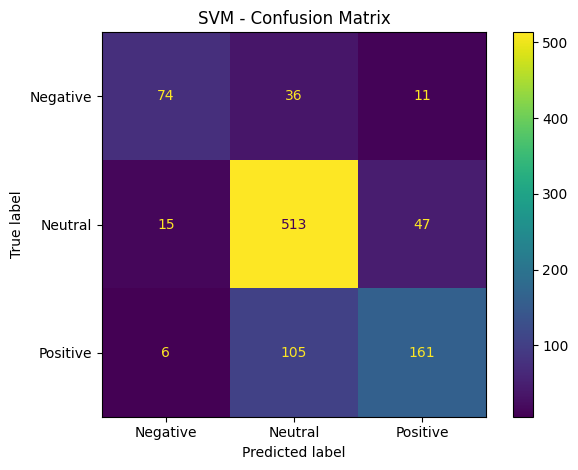

In [13]:

import time
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Build SVM pipeline
svm_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(
        random_state=42,
        max_iter=5000
    ))
])

# Train and calculate training time
start_time = time.time()
svm_model.fit(X_train, y_train)
svm_training_time = time.time() - start_time

# Predict test data
svm_pred = svm_model.predict(X_test)

# Evaluate
print("SVM + TF-IDF")
print("-" * 40)
print("Accuracy :", round(accuracy_score(y_test, svm_pred), 4))
print("Precision:", round(precision_score(
    y_test, svm_pred, average="weighted", zero_division=0
), 4))
print("Recall   :", round(recall_score(
    y_test, svm_pred, average="weighted", zero_division=0
), 4))
print("F1-score :", round(f1_score(
    y_test, svm_pred, average="weighted", zero_division=0
), 4))
print("Training time:", round(svm_training_time, 2), "seconds")

print("\nClassification Report:")
print(classification_report(
    y_test,
    svm_pred,
    labels=[0, 1, 2],
    target_names=["Negative", "Neutral", "Positive"],
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_test, svm_pred, labels=[0, 1, 2])

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)

display.plot(values_format="d")
plt.title("SVM - Confusion Matrix")
plt.tight_layout()
plt.show()


LSTM Model Summary:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)


Training LSTM. Please wait...
Epoch 1/10
109/109 ━━━━━━━━━━━━━━━━━━━━ 14s 103ms/step - accuracy: 0.6187 - loss: 0.8907 - val_accuracy: 0.6951 - val_loss: 0.7691
Epoch 2/10
109/109 ━━━━━━━━━━━━━━━━━━━━ 10s 95ms/step - accuracy: 0.7442 - loss: 0.6078 - val_accuracy: 0.6641 - val_loss: 0.7081
Epoch 3/10
109/109 ━━━━━━━━━━━━━━━━━━━━ 9s 86ms/step - accuracy: 0.8659 - loss: 0.3482 - val_accuracy: 0.7623 - val_loss: 0.7190
Epoch 4/10
109/109 ━━━━━━━━━━━━━━━━━━━━ 11s 98ms/step - accuracy: 0.9486 - loss: 0.1659 - val_accuracy: 0.7209 - val_loss: 0.9284

LSTM training time: 54.73 seconds


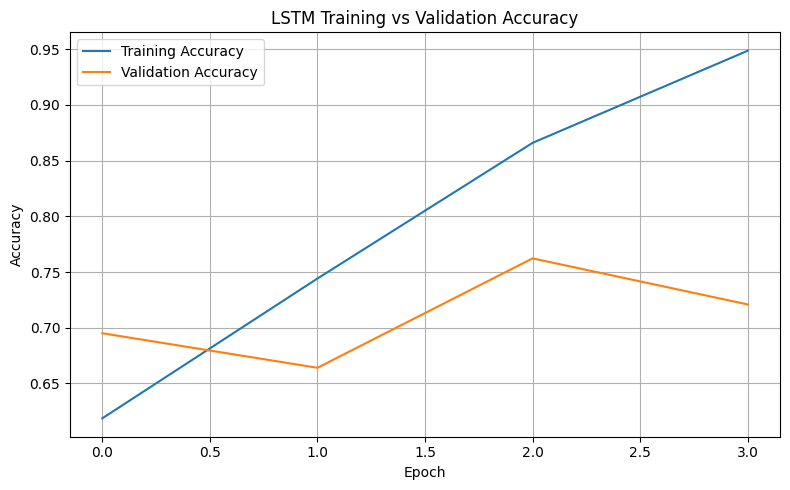

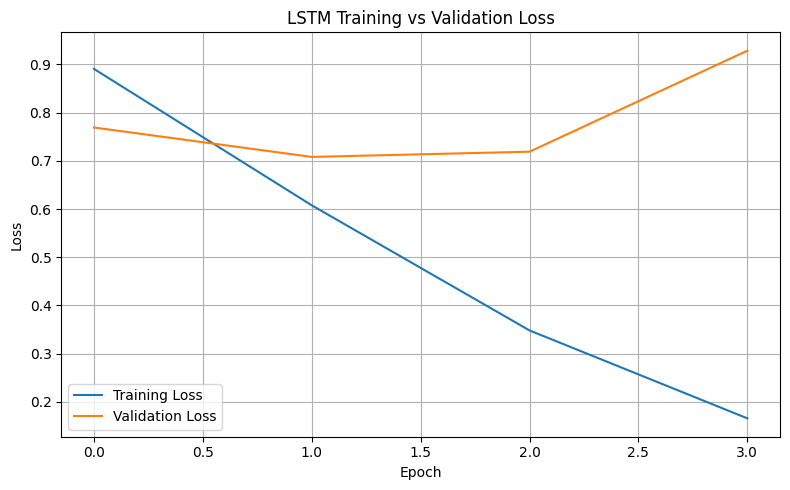


LSTM TEST RESULTS
----------------------------------------
Accuracy : 0.657
Precision: 0.6462
Recall   : 0.657
F1-score : 0.6474

Classification Report:
              precision    recall  f1-score   support

    Negative       0.54      0.32      0.40       121
     Neutral       0.76      0.83      0.79       575
    Positive       0.45      0.45      0.45       272

    accuracy                           0.66       968
   macro avg       0.58      0.53      0.55       968
weighted avg       0.65      0.66      0.65       968



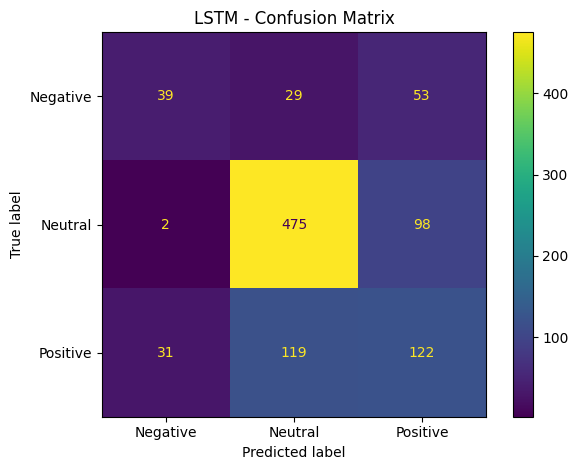


LSTM model saved successfully.


In [14]:

import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Create validation data from training data only
X_lstm_train, X_val, y_lstm_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.10,
    random_state=42,
    stratify=y_train
)

# Tokenize text
MAX_WORDS = 20000
MAX_LENGTH = 100

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_lstm_train)

X_train_seq = pad_sequences(
    tokenizer.texts_to_sequences(X_lstm_train),
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

X_val_seq = pad_sequences(
    tokenizer.texts_to_sequences(X_val),
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

X_test_seq = pad_sequences(
    tokenizer.texts_to_sequences(X_test),
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

# Prepare three-class labels
y_train_lstm = tf.keras.utils.to_categorical(
    y_lstm_train, num_classes=3
)
y_val_lstm = tf.keras.utils.to_categorical(
    y_val, num_classes=3
)

# Build LSTM model
lstm_model = Sequential([
    Embedding(
        input_dim=MAX_WORDS,
        output_dim=64,
        mask_zero=True
    ),
    LSTM(64),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dropout(0.2),
    Dense(3, activation="softmax")
])

lstm_model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("LSTM Model Summary:")
lstm_model.summary()

# Stop early if validation loss stops improving
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

# Train model
print("\nTraining LSTM. Please wait...")

start_time = time.time()

history = lstm_model.fit(
    X_train_seq,
    y_train_lstm,
    validation_data=(X_val_seq, y_val_lstm),
    epochs=10,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

lstm_training_time = time.time() - start_time

print("\nLSTM training time:",
      round(lstm_training_time, 2), "seconds")

# Plot training and validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("LSTM Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Plot training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("LSTM Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Evaluate on the same held-out test set
lstm_probabilities = lstm_model.predict(
    X_test_seq,
    verbose=0
)

lstm_pred = np.argmax(lstm_probabilities, axis=1)

print("\nLSTM TEST RESULTS")
print("-" * 40)
print("Accuracy :", round(
    accuracy_score(y_test, lstm_pred), 4
))
print("Precision:", round(
    precision_score(y_test, lstm_pred,
                    average="weighted", zero_division=0), 4
))
print("Recall   :", round(
    recall_score(y_test, lstm_pred,
                 average="weighted", zero_division=0), 4
))
print("F1-score :", round(
    f1_score(y_test, lstm_pred,
             average="weighted", zero_division=0), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    lstm_pred,
    labels=[0, 1, 2],
    target_names=["Negative", "Neutral", "Positive"],
    zero_division=0
))

# LSTM confusion matrix
cm = confusion_matrix(y_test, lstm_pred, labels=[0, 1, 2])

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)

display.plot(values_format="d")
plt.title("LSTM - Confusion Matrix")
plt.tight_layout()
plt.show()

# Save trained model
lstm_model.save("financial_phrasebank_lstm.keras")

print("\nLSTM model saved successfully.")


FINAL MODEL COMPARISON
              Model  Accuracy  Precision  Recall  F1-Score  Training Time (seconds)
Logistic Regression    0.7624     0.7747  0.7624    0.7429                   2.7980
                SVM    0.7727     0.7699  0.7727    0.7658                   0.8745
               LSTM    0.6570     0.6462  0.6570    0.6474                  54.7252


AttributeError: type object 'CategoricalDtype' has no attribute '_get_plot_converter'

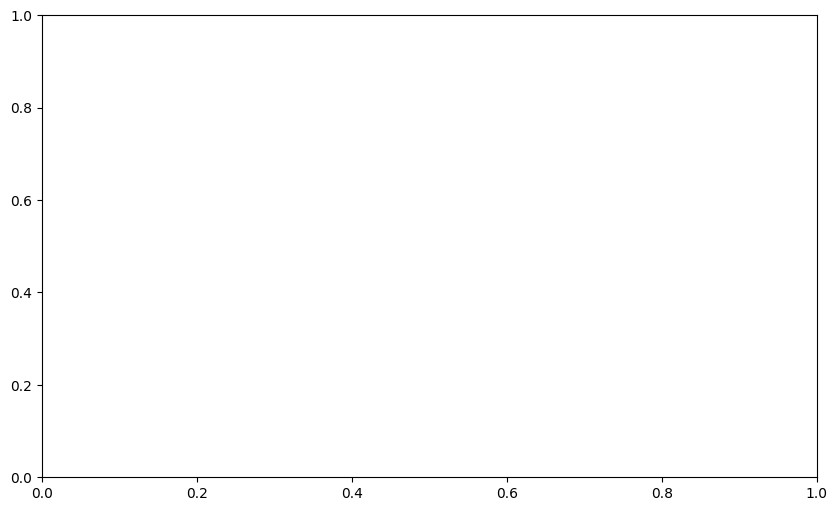

In [15]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Collect results from all three trained models
models = {
    "Logistic Regression": (y_test, lr_pred, lr_training_time),
    "SVM": (y_test, svm_pred, svm_training_time),
    "LSTM": (y_test, lstm_pred, lstm_training_time)
}

comparison = []

for name, (actual, predicted, training_time) in models.items():
    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(
            actual, predicted,
            average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            actual, predicted,
            average="weighted", zero_division=0
        ),
        "F1-Score": f1_score(
            actual, predicted,
            average="weighted", zero_division=0
        ),
        "Training Time (seconds)": training_time
    })

results_df = pd.DataFrame(comparison)

print("FINAL MODEL COMPARISON")
print("=" * 70)
print(results_df.round(4).to_string(index=False))

# Plot comparison of evaluation metrics
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1)
)

plt.title("Sentiment Analysis Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("task2_model_comparison.png", dpi=300)
plt.show()

# Save numerical results
results_df.to_csv("task2_model_comparison.csv", index=False)

print("\nComparison table saved: task2_model_comparison.csv")
print("Comparison graph saved: task2_model_comparison.png")

# Identify the highest weighted F1-score
best_model = results_df.loc[results_df["F1-Score"].idxmax()]

print("\nBest model by weighted F1-score:", best_model["Model"])
print("Weighted F1-score:", round(best_model["F1-Score"], 4))


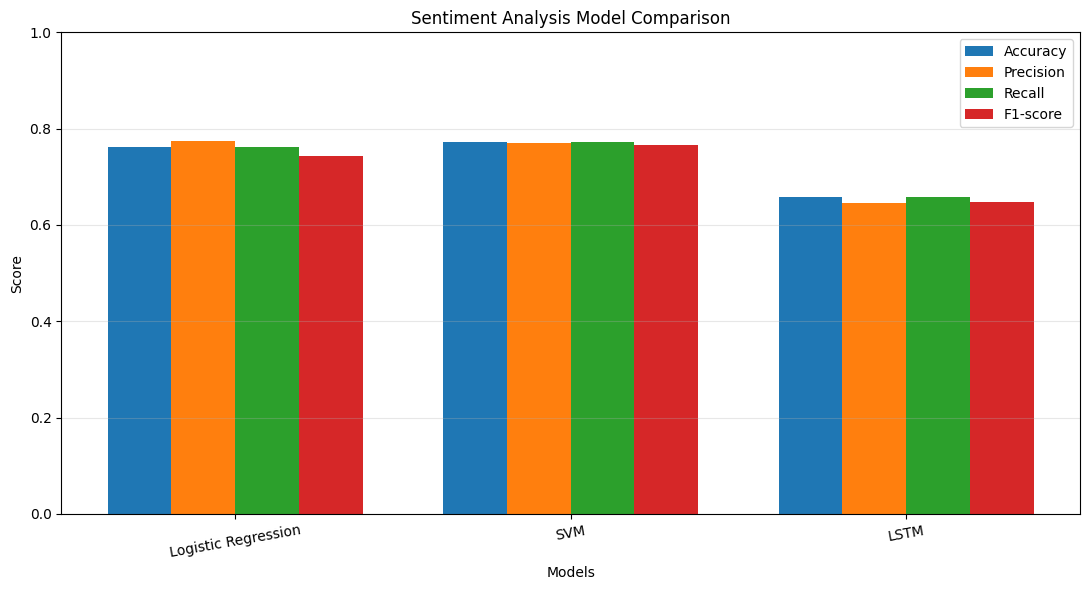

Comparison graph saved successfully!


In [16]:

import matplotlib.pyplot as plt
import numpy as np

model_names = [
    "Logistic Regression",
    "SVM",
    "LSTM"
]

accuracy = [0.7624, 0.7727, 0.6570]
precision = [0.7747, 0.7699, 0.6462]
recall = [0.7624, 0.7727, 0.6570]
f1_score = [0.7429, 0.7658, 0.6474]

x = np.arange(len(model_names))
width = 0.19

plt.figure(figsize=(11, 6))

plt.bar(x - 1.5 * width, accuracy, width, label="Accuracy")
plt.bar(x - 0.5 * width, precision, width, label="Precision")
plt.bar(x + 0.5 * width, recall, width, label="Recall")
plt.bar(x + 1.5 * width, f1_score, width, label="F1-score")

plt.title("Sentiment Analysis Model Comparison")
plt.xlabel("Models")
plt.ylabel("Score")
plt.xticks(x, model_names, rotation=10)
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("task2_model_comparison.png", dpi=300)
plt.show()

print("Comparison graph saved successfully!")


In [17]:

# Save final model comparison
results_df.to_csv("task2_model_comparison.csv", index=False)

# Save detailed classification reports
from sklearn.metrics import classification_report

with open("task2_classification_reports.txt", "w") as f:
    f.write("iNeuBytes Task 2 - Sentiment Analysis Results\n")
    f.write("=" * 55 + "\n\n")

    for name, predictions in [
        ("Logistic Regression + TF-IDF", lr_pred),
        ("SVM + TF-IDF", svm_pred),
        ("LSTM", lstm_pred)
    ]:
        f.write(name + "\n")
        f.write("-" * 40 + "\n")
        f.write(classification_report(
            y_test,
            predictions,
            labels=[0, 1, 2],
            target_names=["Negative", "Neutral", "Positive"],
            zero_division=0
        ))
        f.write("\n\n")

print("Saved: task2_model_comparison.csv")
print("Saved: task2_classification_reports.txt")
print("Saved: task2_model_comparison.png")


Saved: task2_model_comparison.csv
Saved: task2_classification_reports.txt
Saved: task2_model_comparison.png


In [18]:

from google.colab import files

files.download("task2_model_comparison.csv")
files.download("task2_classification_reports.txt")
files.download("task2_model_comparison.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>